#LLM - Klasyczne metody klasyfikacji tekstu - LAB

#Zadanie

Zaadaptuj kod z notatnika *LLM - Klasyczne metody klasyfikacji tekstu - Omówienie* do problemu klasyfikacji liczby gwiazdek dla opinii z serwisu Yelp.
Możesz przygotować pętlę treningową albo w czystym PyTorchu, albo z wykorzystaniem biblioteki PyTorch Lightning.

* Wykorzystaj zbiór `Yelp/yelp_review_full` ([link](https://huggingface.co/datasets/Yelp/yelp_review_full)) zawierający opinie z serwisu Yelp (kolumna: `text`) i etykietę (kolumna: `label`) o wartościach $0,1,2,3,4$ określającą liczbę gwiazdek przyznaną przez użytkownika (a ściślej, liczbę gwiazdek minus jeden). Ponieważ mamy pięć klas, ostatnia warstwa liniowa w sieci neuronowej musi zwracać pięć wartości.
    * Zgodnie z dobrą praktyką z części treningowej wydziel dodatkową część walidacyjną i testową.
    * Ogranicz rozmiar każdej części zbioru danych (treningowej, walidacyjnej i testowej). Część treningowa nie powinna zawierać więcej niż 100k elementów.
* Do ekstrakcji cech z tekstu wykorzystaj **metodę TF-IDF** (*term frequency-inverse document frequency*) opartą o podejście typu worek słów (*bag-of-words*). Zastosuj funkcję `TfidfVectorizer` z biblioteki `scikit-learn`.
* Wykorzystaj podobną architekturę sieci (perceptron wielowarstwowy z warstwą Dropout) jak w notatniku wykładowym.



## Punkty do wykonania

1.   Napisz funkcję znajdującą i wyświetlającą $k$ elementów zbioru testowego dla których model najbardziej się myli, czyli estymuje najmniejsze prawdopodobieństwa prawdziwej klasy. Softmax jest funkcją ściśle rosnącą, więc wystarczy znaleźć elementy z najmniejszą wartością nieznormalizowanego wyjścia z sieci (logita) dla prawdziwej klasy.
2.   Zbadaj wpływ wybranych parametrów funkcji ekstrakcji cech z tekstu `TfidfVectorizer` na skuteczność wytrenowanego modelu. Uruchom kilka eksperymentów z różnymi wartościami parametrów i porównaj dokładność wytrenowanego modelu na zbiorze walidacyjnym.
3.   Zbadaj wpływ wybranych hiperparametrów modelu (np. liczba warstw liniowych modelu, rozmiary warstw) i procesu uczenia (np. początkowa wartość stopy uczenia, liczba epok, typ i parametry planisty stopy uczenia, typ i parametry optymalizatora) na skuteczność wytrenowanego modelu. Uruchom kilka eksperymentów z różnymi wartościami hiperparametrów i porównaj dokładność wytrenowanego modelu na zbiorze walidacyjnym. Następnie wykonaj finalną ewaluację najlepszego modelu na zbiorze testowym.


##Przygotowanie środowiska
Upewnij się, że notatnik jest uruchomiony na maszynie z GPU. Jesli GPU nie jest dostępne zmień typ maszyny (Runtime | Change runtime type) i wybierz T4 GPU.

In [47]:
# !nvidia-smi

Instalacja dodatkowych bibliotek: datasets (z biblioteki HuggingFace), TorchMetrics i W&B (Weights and Biases) Models.

In [48]:
!pip install -q datasets
!pip install -q torchmetrics
!pip install -q wandb

Import bibliotek.

In [49]:
import torch
import numpy as np
import matplotlib.pyplot as plt

print(f"Wersja biblioteki PyTorch: {torch.__version__}")

Wersja biblioteki PyTorch: 2.10.0


Sprawdzenie dostępności GPU.

In [50]:
print(f"Dostępność GPU CUDA: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Typ GPU: {torch.cuda.get_device_name(0)}")

print(f"Dostępność GPU MPS: {torch.mps.is_available()}")

Dostępność GPU CUDA: False
Dostępność GPU MPS: True


In [51]:
import wandb
import os


os.environ["WANDB_MODE"] = "offline"

# Logowanie do serwisu Weights&Biases monitorującego przebieg eksperymentów
# wandb.login(3)

# Solution

## Data processing and analyzation

In [52]:
from datasets import load_dataset


dataset = load_dataset("Yelp/yelp_review_full")

test_dataset = dataset["test"]
train_val_dataset = dataset["train"].train_test_split(test_size=0.2)
train_dataset = train_val_dataset["train"]
val_dataset = train_val_dataset["test"]

print(train_dataset.shape)
print(val_dataset.shape)
print(test_dataset.shape)

train_dataset = train_dataset.shuffle(seed=42).select(range(int(len(train_dataset)*0.15)))
val_dataset = val_dataset.shuffle(seed=42).select(range(int(len(val_dataset)*0.15)))
test_dataset = test_dataset.shuffle(seed=42).select(range(int(len(test_dataset)*0.15)))

print(f"Liczba próbek w zbiorze treningowym: {len(train_dataset)}")
print(f"Liczba próbek w zbiorze walidacyjnym: {len(val_dataset)}")
print(f"Liczba próbek w zbiorze testowym: {len(test_dataset)}")

(520000, 2)
(130000, 2)
(50000, 2)
Liczba próbek w zbiorze treningowym: 78000
Liczba próbek w zbiorze walidacyjnym: 19500
Liczba próbek w zbiorze testowym: 7500


In [53]:
id = int(np.random.choice(range(len(train_dataset))))
print(f"Row={id}")
sample = train_dataset[id]
print(f"{sample['text']=}")
print(f"{sample['label']=}")

Row=22973
sample['text']="Let me begin by saying I hate buffets.  I don't want to eat a huge amount of food in a sitting and I don't like that the food is often basic and boring made to appeal to the masses.  So when I give Wicked Spoon 4 stars, that's crazy-high praise. And you'll see that I clearly had a totally ridiculous amount of food. And needed a big nap for the next few hours.\\n\\nWe stayed at the Cosmopolitan for 2 nights and were allowed to enter both mornings for free so we visited the breakfast buffet twice.  For Elite Marriott members, the hotel does not offer a club-level breakfast so this is the amazing concession.  \\n\\nGot in line around 9:30A the first morning and it was a 20-30 minute wait.  Asked the cashier if we could go right in but were told we needed to wait in line.  No worries, but we did see others ask the same question and get seated right away.  Mentioned that the 2nd day since we got up a bit later and the line was a bit longer and the cashier said we w

Unique labels: [0 1 2 3 4], Number of unique labels: 5



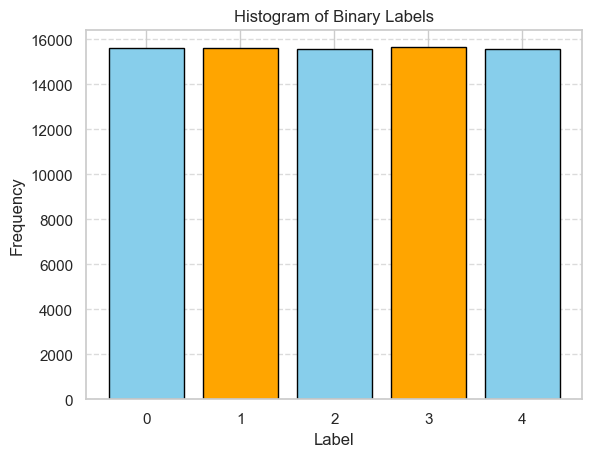

In [54]:
# Count occurrences of each label
unique_labels, counts = np.unique(train_dataset['label'], return_counts=True)
labels_num = len(unique_labels)
print(f"Unique labels: {unique_labels}, Number of unique labels: {labels_num}\n")

# Plot histogram
plt.bar(unique_labels, counts, color=['skyblue', 'orange'], edgecolor='black')
plt.title('Histogram of Binary Labels')
plt.xlabel('Label')
plt.ylabel('Frequency')
plt.xticks(unique_labels)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [55]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [56]:
vocab_size = 1000

vectorizer = TfidfVectorizer(
    max_features=vocab_size,
    lowercase=True,
    analyzer="word",
    ngram_range=(1, 1),
    stop_words="english"
)

train_features = vectorizer.fit_transform(train_dataset["text"])

val_features = vectorizer.transform(val_dataset["text"])
test_features = vectorizer.transform(test_dataset["text"])

In [57]:
print(f"TF-IDF Matric size for train dataset: {train_features.shape}")   # 78 000 rows - number of documents in (language) corpus, 1 000 columns - number of word features with weights
print(f"{train_features.dtype=}\n")

feature_names = vectorizer.get_feature_names_out()
print(f"Extracted features number: {len(feature_names)}")
print(f"Sample features: {np.random.choice(feature_names, 30)}\n")

TF-IDF Matric size for train dataset: (78000, 1000)
train_features.dtype=dtype('float64')

Extracted features number: 1000
Sample features: ['cup' 'using' 'bars' 'fact' 'cook' 'order' 'cheap' 'drive' 'bag'
 'italian' 'chef' 'difficult' 'expect' 'close' 'bad' 'change' 'delivered'
 'places' 'turkey' 'club' 'garlic' 'movie' 'flavor' 'running' 'hotels'
 'nice' 'establishment' 'meal' 'terrible' 'given']



In [58]:
ndx = int(np.random.choice(range(len(train_dataset))))
print(f"Train dataset element with index={ndx}")
print(f"{train_dataset['text'][ndx]=}\n")

features = train_features[ndx]  # features extracted from document of `ndx` index out of 78 000 documents in language corpus
print(f"No-filtered features: {features}\n")  # Compressed Sparse Row sparse matrix ... shape (1, 1000) -> each feature is addressed like (0, 356)

print(f"Features of element with index={ndx}:")
non_zero_cols = features.nonzero()[1]

non_zero_cols = sorted(non_zero_cols)
for i in non_zero_cols:
    print(f"Column: {i} ({feature_names[i]})   Weight: {features[0, i]:.5f}") # coords od each feature in row/document is (0, <column_numb>)

Train dataset element with index=18219
train_dataset['text'][ndx]='Great food, cool atmosphere'

No-filtered features: <Compressed Sparse Row sparse matrix of dtype 'float64'
	with 4 stored elements and shape (1, 1000)>
  Coords	Values
  (0, 172)	0.6372542636300546
  (0, 362)	0.3535702860116852
  (0, 320)	0.305777226450043
  (0, 41)	0.6126951477851371

Features of element with index=18219:
Column: 41 (atmosphere)   Weight: 0.61270
Column: 172 (cool)   Weight: 0.63725
Column: 320 (food)   Weight: 0.30578
Column: 362 (great)   Weight: 0.35357


Mean of non-zero features in samples: 32.36


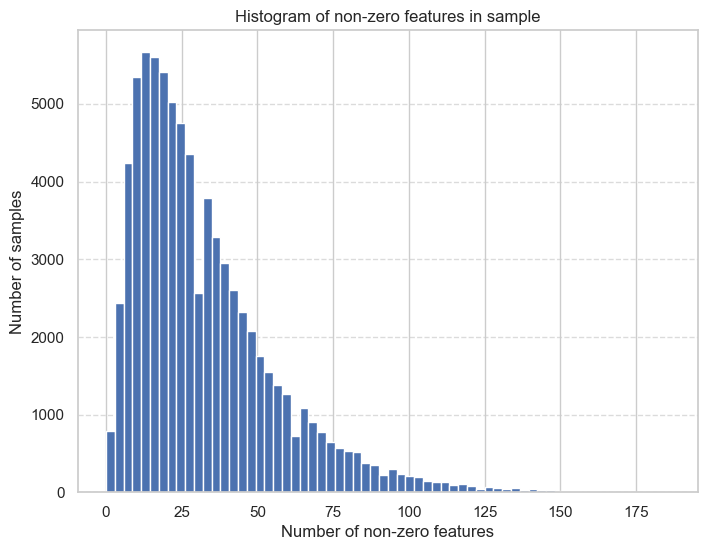

In [59]:
non_zero_counts = np.diff(train_features.indptr)
print(f"Mean of non-zero features in samples: {non_zero_counts.mean():.2f}")  # średnia liczba cech wyodrębnionych per dokument z korpusu językowego (średnia wartość dla 1 z 67 200)

# Plot histogram
plt.figure(figsize=(8, 6))
plt.hist(non_zero_counts, bins=64)
plt.title('Histogram of non-zero features in sample')
plt.xlabel('Number of non-zero features')
plt.ylabel('Number of samples')
plt.grid(axis='y', linestyle='--', alpha=0.7)

In [60]:
import torch

from torch.utils.data import TensorDataset, DataLoader

In [61]:
def make_dataset(sparse_features, labels):
    dense_features = sparse_features.astype(np.float32).todense()     # scipy.sparse.spmatrix.todense() --> numpy.matrix
    dataset = TensorDataset(
        torch.from_numpy(dense_features),
        torch.tensor(labels, dtype=torch.int64)
    )
    return dataset


# print(type(train_features))           # type: scipy.sparse._csr.csr_matrix
# print(type(train_dataset['label']))   # type: datasets.arrow_dataset.Column

datasets = {
    'train': make_dataset(train_features, train_dataset['label']),
    'val': make_dataset(val_features, val_dataset['label']),
    'test': make_dataset(test_features, test_dataset['label'])
}

print(datasets['train'][0])

(tensor([0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.2355, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.2374, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000,

In [62]:
batch_size = 128

data_loaders = {stage: DataLoader(datasets[stage], shuffle=stage=="train", num_workers=0, batch_size=batch_size) for stage in datasets}

In [63]:
for X_batch, y_batch in data_loaders['train']:
    print(f"{X_batch.shape=}")
    print(f"{y_batch.shape=}")
    break

X_batch.shape=torch.Size([128, 1000])
y_batch.shape=torch.Size([128])


## Stage 0 - basic model + train loop + helper functions definion

In [64]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "mps" if torch.mps.is_available() else "cpu")
print(f"Device: {device}")

Device: mps


In [65]:
import torch.nn as nn


class RatingClassifier(nn.Module):
    def __init__(self, vocab_size: int, n_classes: int):
        super().__init__()
        self.vocab_size = vocab_size
        self.n_classes = n_classes

        self.feature_extractor = nn.Sequential(
            nn.Linear(self.vocab_size, 64),
            nn.LeakyReLU(),
            nn.Linear(64, 128),
            nn.LeakyReLU(),
            nn.Linear(128, 32),
            nn.LeakyReLU(),
        )
        self.dropout = nn.Dropout(0.1)
        self.linear = nn.Linear(32, n_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        features = self.feature_extractor(x)
        features = self.dropout(features)
        logits = self.linear(features)
        return logits

#### Model Training loop

In [66]:
import torch.nn as nn
import torchmetrics
from tqdm import tqdm


def train(model: nn.Module, loaders: dict[DataLoader], criterion: nn.Module,
          optimizer: torch.optim.Optimizer, lr_scheduler, num_epochs: int):

    accumulated_loss = []
    accumulated_acc = []

    metric_loss = torchmetrics.aggregation.MeanMetric().to(device)
    metric_acc = torchmetrics.classification.Accuracy(task="multiclass", num_classes=labels_num).to(device)

    # val_loss = np.array(np.inf)
    # overfitting_counter = 0

    for epoch in range(1, num_epochs+1):

        for phase in ['train', 'val']:
            if phase == 'train':
                model.train()
            else:
                model.eval()

            for X_batch, target in tqdm(loaders[phase]):

                X_batch, target = X_batch.to(device), target.to(device)

                optimizer.zero_grad()

                with torch.set_grad_enabled(phase == 'train'):
                    logits = model(X_batch)
                    # dim=1, as columns (dim=1) are 'squeezed' to one max value
                    _, preds = torch.max(logits, dim=1)   # torch.max() --> [values, indices] - pred is index of max value as in softmax highest value will have highest prob as well
                    loss = criterion(logits, target)

                    metric_loss(loss)
                    metric_acc(preds, target)

                    if phase == 'train':
                        loss.backward()
                        optimizer.step()

            acc = metric_acc.compute()
            mean_loss = metric_loss.compute()
            current_lr = lr_scheduler.get_last_lr()[0]

            ### earlier training stopping , used in testing
            # if phase == "val":
            #     if mean_loss.to_numpy() > val_loss:
            #         overfitting_counter += 1
            #     else:
            #         val_loss = mean_loss.to_numpy()

            print(f"(Epoch {epoch}/[{phase}]) Loss:\t{mean_loss:.3f}   Accuracy: {acc:.3f}   lr: {current_lr}")
            metrics = {
                f"{phase}/loss": mean_loss,
                f"{phase}/accuracy": acc,
                f"{phase}/lr": current_lr,
            }
            wandb.log(metrics, step=epoch)

            if phase == "val":
                accumulated_loss.append(float(mean_loss.cpu()))
                accumulated_acc.append(float(acc.cpu()))

            metric_loss.reset()
            metric_acc.reset()

            # if overfitting_counter > 5:
            #     break

        lr_scheduler.step()

    return accumulated_loss, accumulated_acc


In [67]:
def find_worst_predictions(logits: torch.Tensor, targets: torch.Tensor, k=5):
    logit_per_true_class = logits.gather(dim=1, index=targets.view(-1, 1)).squeeze(1)
    values, indices = torch.topk(logit_per_true_class, k=k, largest=False)
    return values, indices

In [68]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt


def plot_confusion_matrix(targets, preds):
    cm = confusion_matrix(targets, preds, normalize="true")
    plt.figure(figsize=(10, 8))
    classes = list(range(labels_num))
    sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues', 
                xticklabels=classes, yticklabels=classes)
    plt.xlabel("Prediction")
    plt.ylabel("True class")
    plt.title("Confussion matrix")
    plt.show()



In [69]:
def plot_comparison(metric_dict, title, ylabel):
    sns.set_theme(style="whitegrid")
    
    fig, ax = plt.subplots(figsize=(12, 6), constrained_layout=False)

    for model_name, metrics_val in metric_dict.items():
        epochs = range(1, len(metrics_val) + 1)
        plt.plot(epochs, metrics_val, label=model_name, linewidth=2, marker='o', markersize=4)

    ax.set_title(title, fontsize=14, fontweight="bold")
    ax.set_xlabel("Epoch", fontsize=12)
    ax.set_ylabel(ylabel, fontsize=12)
    ax.grid(True, linestyle="--", alpha=0.7)

    fig.subplots_adjust(right=0.72)

    leg = ax.legend(
        loc="center left",
        bbox_to_anchor=(1.02, 0.5),
        frameon=True,
        title="Experiment legend",
        borderaxespad=0.0
    )
    leg.get_frame().set_alpha(1.0)

    plt.show()

## Stage 1 - simple test model training + finding `k` worst preds for true class

In [70]:
classifier = RatingClassifier(vocab_size, n_classes=labels_num)
classifier.to(device)

print(classifier)

RatingClassifier(
  (feature_extractor): Sequential(
    (0): Linear(in_features=1000, out_features=64, bias=True)
    (1): LeakyReLU(negative_slope=0.01)
    (2): Linear(in_features=64, out_features=128, bias=True)
    (3): LeakyReLU(negative_slope=0.01)
    (4): Linear(in_features=128, out_features=32, bias=True)
    (5): LeakyReLU(negative_slope=0.01)
  )
  (dropout): Dropout(p=0.1, inplace=False)
  (linear): Linear(in_features=32, out_features=5, bias=True)
)


In [71]:
num_epochs = 30

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(classifier.parameters(), lr=1e-4, weight_decay=1e-5)
lr_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs, eta_min=1e-5)

In [72]:
run = wandb.init(project="MyExperiments")

_, _ = train(classifier, data_loaders, criterion, optimizer, lr_scheduler, num_epochs)

run.finish()

100%|██████████| 610/610 [00:04<00:00, 152.26it/s]


(Epoch 1/[train]) Loss:	1.481   Accuracy: 0.347   lr: 0.0001


100%|██████████| 153/153 [00:00<00:00, 233.23it/s]


(Epoch 1/[val]) Loss:	1.205   Accuracy: 0.477   lr: 0.0001


100%|██████████| 610/610 [00:03<00:00, 161.62it/s]


...

100%|██████████| 610/610 [00:03<00:00, 158.89it/s]


(Epoch 30/[train]) Loss:	1.031   Accuracy: 0.554   lr: 1.0246514708427697e-05


100%|██████████| 153/153 [00:00<00:00, 233.30it/s]
wandb: ERROR The nbformat package was not found. It is required to save notebook history.


(Epoch 30/[val]) Loss:	1.051   Accuracy: 0.549   lr: 1.0246514708427697e-05


train/accuracy,▁▆▇███████████████████████████
train/loss,█▃▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train/lr,██████▇▇▇▇▆▆▆▅▅▄▄▄▃▃▃▂▂▂▂▁▁▁▁▁
val/accuracy,▁▆████████████████████████████
val/loss,█▃▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val/lr,██████▇▇▇▇▆▆▆▅▅▄▄▄▃▃▃▂▂▂▂▁▁▁▁▁
train/accuracy,0.55394
train/loss,1.03074
train/lr,1e-05
val/accuracy,0.54887
val/loss,1.05085


In [73]:
logits_l = []
preds_l = []
targets_l = []
input_l = []

classifier.eval()
with torch.inference_mode():
    for X_batch, target in tqdm(data_loaders['test']):
        X_batch, target = X_batch.to(device), target.to(device)
        logits = classifier(X_batch)
        _, preds = torch.max(logits, dim=-1)
        preds_l.append(preds.cpu())
        logits_l.append(logits.cpu())
        targets_l.append(target.cpu())
        input_l.append(X_batch.cpu())

all_logits = torch.cat(logits_l, dim=0)
all_preds = torch.cat(preds_l, dim=0)
all_targets = torch.cat(targets_l, dim=0)
all_input = torch.cat(input_l, dim=0)

find_worst_predictions(all_logits, all_targets)

100%|██████████| 59/59 [00:00<00:00, 320.02it/s]


(tensor([-4.2342, -4.1004, -3.4877, -2.9534, -2.7205]),
 tensor([5240, 1710, 6155, 5760, 3469]))

## Stage 2 - finding best Vectorizer params

In [74]:
from dataclasses import dataclass, asdict


@dataclass
class VectorizerParams:
      max_features: int
      lowercase: bool
      analyzer: str
      ngram_range: tuple[int, int]
      stop_words: str = "english"



def prep_dataloaders(params: VectorizerParams, datasets: list, batch_size: int = 128):

    vectorizer = TfidfVectorizer(**asdict(params))

    train_dataset, val_dataset, test_dataset = datasets

    train_features = vectorizer.fit_transform(train_dataset["text"])

    val_features = vectorizer.transform(val_dataset["text"])
    test_features = vectorizer.transform(test_dataset["text"])


    datasets = {
        'train': make_dataset(train_features, train_dataset['label']),
        'val': make_dataset(val_features, val_dataset['label']),
        'test': make_dataset(test_features, test_dataset['label'])
    }

    batch_size = 256

    return {stage: DataLoader(datasets[stage], shuffle=stage=="train", num_workers=0, batch_size=batch_size) for stage in datasets}


In [75]:
vectorizers = [
    VectorizerParams(max_features=100, lowercase=True, analyzer="word", ngram_range=(1, 1)),
    VectorizerParams(max_features=1000, lowercase=False, analyzer="word", ngram_range=(1, 2)),
    VectorizerParams(max_features=1000, lowercase=True, analyzer="word", ngram_range=(2, 2)),
    VectorizerParams(max_features=10000, lowercase=True, analyzer="word", ngram_range=(1, 1)),
    VectorizerParams(max_features=10000, lowercase=True, analyzer="word", ngram_range=(1, 3))
]

In [76]:
all_tested_losses = {}
all_tested_acc = {}

plain_datasets = (train_dataset, val_dataset, test_dataset)
num_epochs = 10

for vectorizer in vectorizers:
    classifier = RatingClassifier(vectorizer.max_features, n_classes=labels_num)
    classifier.to(device)

    print(classifier)
    print(f"{vectorizer}\n")

    data_loaders = prep_dataloaders(vectorizer, plain_datasets)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(classifier.parameters(), lr=1e-4, weight_decay=1e-5)
    lr_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs, eta_min=1e-5)

    run = wandb.init(project="MyExperiments")
    accumulated_loss, accumulated_acc = train(classifier, data_loaders, criterion, optimizer, lr_scheduler, num_epochs)
    run.finish()
    
    all_tested_losses[str(vectorizer)] = accumulated_loss
    all_tested_acc[str(vectorizer)] = accumulated_acc


RatingClassifier(
  (feature_extractor): Sequential(
    (0): Linear(in_features=100, out_features=64, bias=True)
    (1): LeakyReLU(negative_slope=0.01)
    (2): Linear(in_features=64, out_features=128, bias=True)
    (3): LeakyReLU(negative_slope=0.01)
    (4): Linear(in_features=128, out_features=32, bias=True)
    (5): LeakyReLU(negative_slope=0.01)
  )
  (dropout): Dropout(p=0.1, inplace=False)
  (linear): Linear(in_features=32, out_features=5, bias=True)
)
VectorizerParams(max_features=100, lowercase=True, analyzer='word', ngram_range=(1, 1), stop_words='english')



100%|██████████| 305/305 [00:01<00:00, 154.92it/s]


(Epoch 1/[train]) Loss:	1.603   Accuracy: 0.247   lr: 0.0001


100%|██████████| 77/77 [00:00<00:00, 208.23it/s]


(Epoch 1/[val]) Loss:	1.572   Accuracy: 0.344   lr: 0.0001


...

100%|██████████| 305/305 [00:05<00:00, 56.97it/s]


(Epoch 10/[train]) Loss:	0.902   Accuracy: 0.605   lr: 1.2202456766718093e-05


100%|██████████| 77/77 [00:01<00:00, 66.27it/s]
wandb: ERROR The nbformat package was not found. It is required to save notebook history.


(Epoch 10/[val]) Loss:	0.975   Accuracy: 0.575   lr: 1.2202456766718093e-05


train/accuracy,▁▅▆▇▇█████
train/loss,█▄▃▂▂▁▁▁▁▁
train/lr,██▇▇▆▄▃▂▂▁
val/accuracy,▁▄▅▇▇█████
val/loss,█▃▂▂▁▁▁▁▁▁
val/lr,██▇▇▆▄▃▂▂▁
train/accuracy,0.60515
train/loss,0.9019
train/lr,1e-05
val/accuracy,0.57456
val/loss,0.97512


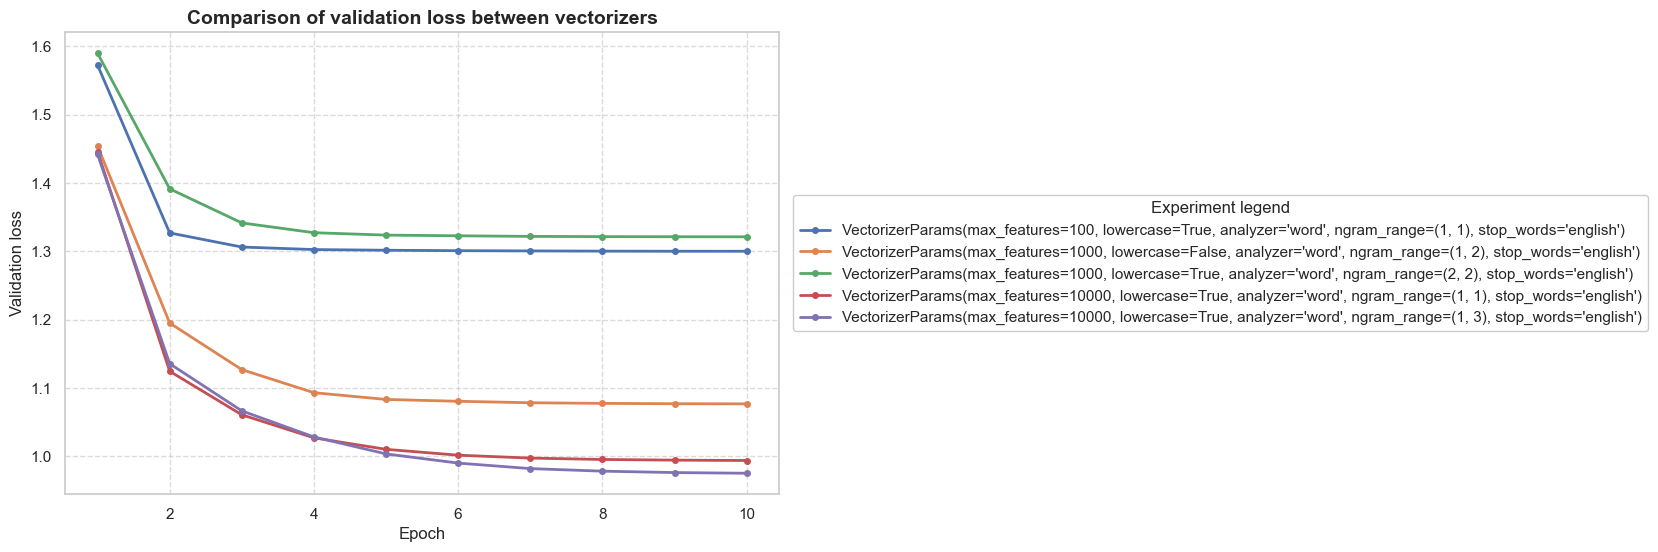

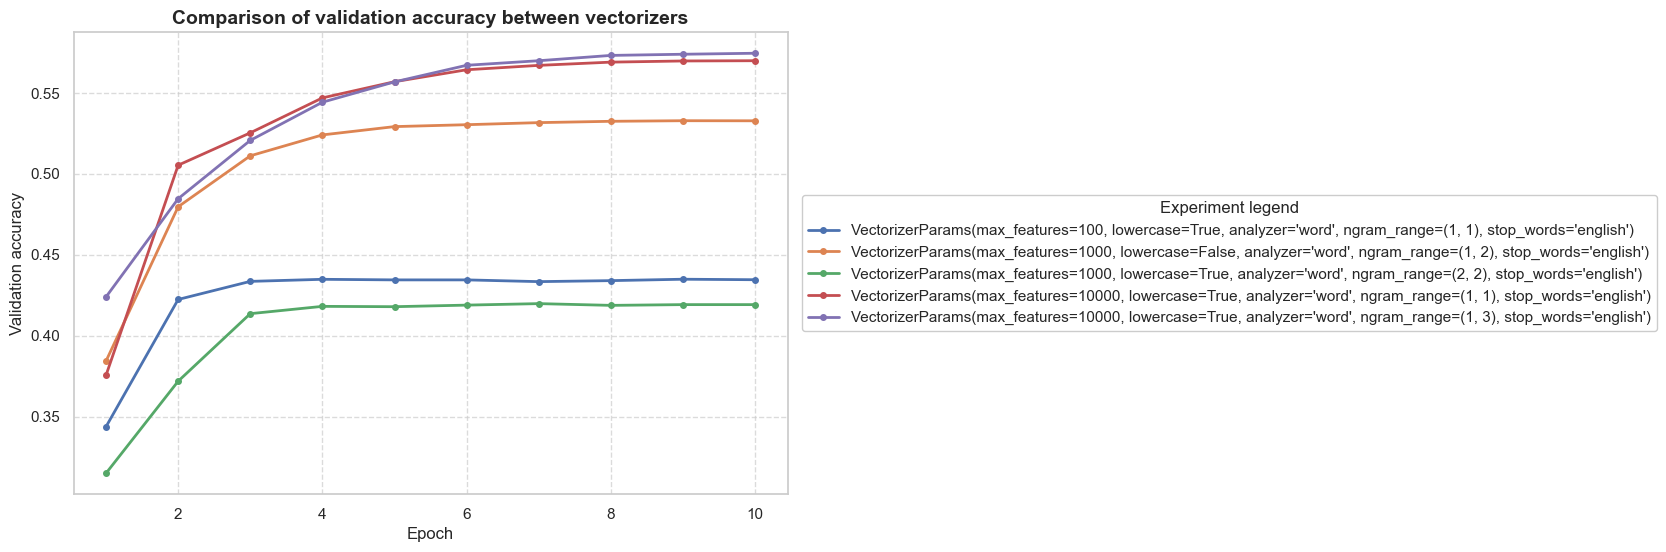

In [77]:
plot_comparison(all_tested_losses, title="Comparison of validation loss between vectorizers", ylabel="Validation loss")
plot_comparison(all_tested_acc, title="Comparison of validation accuracy between vectorizers", ylabel="Validation accuracy")

#### Training + Evaluation on test dataset for data transformed by best found vectorizer 

In [78]:
vectorizer = VectorizerParams(max_features=10000, lowercase=True, analyzer="word", ngram_range=(1, 3))

classifier = RatingClassifier(vectorizer.max_features, n_classes=labels_num)
classifier.to(device)

print(classifier)

data_loaders = prep_dataloaders(vectorizer, plain_datasets)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(classifier.parameters(), lr=1e-4, weight_decay=1e-5)
lr_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs, eta_min=1e-5)

run = wandb.init(project="MyExperiments")
_, _ = train(classifier, data_loaders, criterion, optimizer, lr_scheduler, num_epochs)
run.finish()

RatingClassifier(
  (feature_extractor): Sequential(
    (0): Linear(in_features=10000, out_features=64, bias=True)
    (1): LeakyReLU(negative_slope=0.01)
    (2): Linear(in_features=64, out_features=128, bias=True)
    (3): LeakyReLU(negative_slope=0.01)
    (4): Linear(in_features=128, out_features=32, bias=True)
    (5): LeakyReLU(negative_slope=0.01)
  )
  (dropout): Dropout(p=0.1, inplace=False)
  (linear): Linear(in_features=32, out_features=5, bias=True)
)


100%|██████████| 305/305 [00:05<00:00, 56.76it/s]


(Epoch 1/[train]) Loss:	1.586   Accuracy: 0.277   lr: 0.0001


100%|██████████| 77/77 [00:01<00:00, 72.35it/s]


(Epoch 1/[val]) Loss:	1.464   Accuracy: 0.402   lr: 0.0001


...

100%|██████████| 305/305 [00:05<00:00, 59.07it/s]


(Epoch 10/[train]) Loss:	0.859   Accuracy: 0.630   lr: 1.2202456766718093e-05


100%|██████████| 77/77 [00:01<00:00, 62.56it/s]
wandb: ERROR The nbformat package was not found. It is required to save notebook history.


(Epoch 10/[val]) Loss:	0.960   Accuracy: 0.587   lr: 1.2202456766718093e-05


train/accuracy,▁▅▇▇██████
train/loss,█▄▂▂▁▁▁▁▁▁
train/lr,██▇▇▆▄▃▂▂▁
val/accuracy,▁▇████████
val/loss,█▂▁▁▁▁▁▁▁▁
val/lr,██▇▇▆▄▃▂▂▁
train/accuracy,0.62962
train/loss,0.85929
train/lr,1e-05
val/accuracy,0.58703
val/loss,0.95964


100%|██████████| 30/30 [00:00<00:00, 58.75it/s]


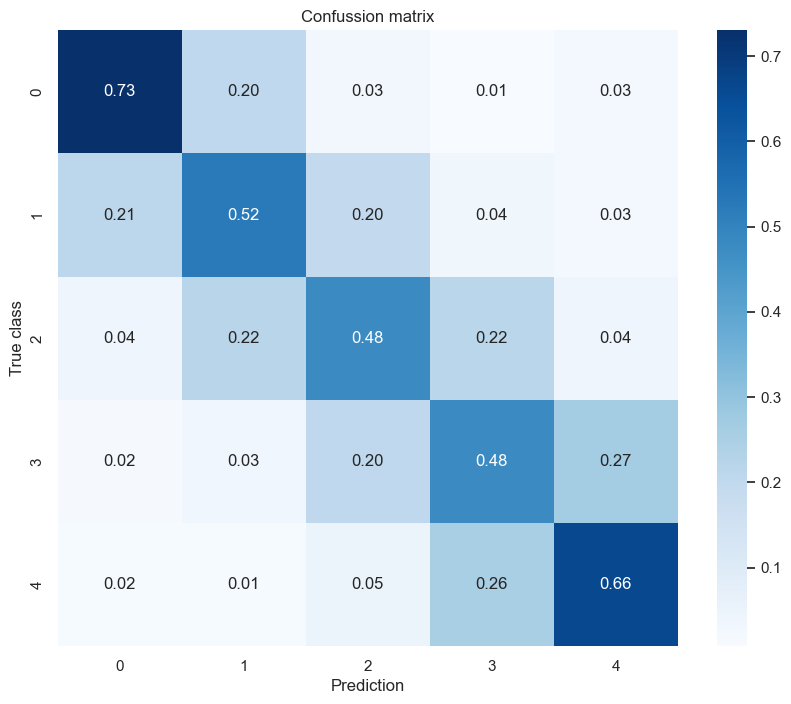

In [79]:
logits_l = []
preds_l = []
targets_l = []
input_l = []

classifier.eval()
with torch.inference_mode():
    for X_batch, target in tqdm(data_loaders['test']):
        X_batch, target = X_batch.to(device), target.to(device)
        logits = classifier(X_batch)
        _, preds = torch.max(logits, dim=-1)
        preds_l.append(preds.cpu())
        logits_l.append(logits.cpu())
        targets_l.append(target.cpu())
        input_l.append(X_batch.cpu())

all_logits = torch.cat(logits_l, dim=0)
all_preds = torch.cat(preds_l, dim=0)
all_targets = torch.cat(targets_l, dim=0)
all_input = torch.cat(input_l, dim=0)

plot_confusion_matrix(all_targets.numpy(), all_preds.numpy())

## Stage 3 - finding best model hiperparams and training stage params

#### New test models with different varianions of neurons number (hidden layers size) and hidden layers number

In [80]:
import torch.nn as nn


class RatingClassifierExtendedV1(nn.Module):
    def __init__(self, vocab_size: int, n_classes: int):
        super().__init__()
        self.vocab_size = vocab_size
        self.n_classes = n_classes

        self.feature_extractor = nn.Sequential(
            nn.Linear(self.vocab_size, 32),
            nn.LeakyReLU(),
        )
        self.dropout = nn.Dropout(0.1)
        self.linear = nn.Linear(32, n_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        features = self.feature_extractor(x)
        features = self.dropout(features)
        logits = self.linear(features)
        return logits
    

class RatingClassifierExtendedV2(nn.Module):
    def __init__(self, vocab_size: int, n_classes: int):
        super().__init__()
        self.vocab_size = vocab_size
        self.n_classes = n_classes

        self.feature_extractor = nn.Sequential(
            nn.Linear(self.vocab_size, 256),
            nn.LeakyReLU(),
            nn.Linear(256, 128),
            nn.LeakyReLU(),
            nn.Linear(128, 64),
            nn.LeakyReLU(),
            nn.Linear(64, 32),
            nn.LeakyReLU(),
            nn.Linear(32, 16),
            nn.LeakyReLU(),
        )
        self.dropout = nn.Dropout(0.1)
        self.linear = nn.Linear(16, n_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        features = self.feature_extractor(x)
        features = self.dropout(features)
        logits = self.linear(features)
        return logits


#### Using vectorizer with best results in stage 2 

In [81]:
vocab_size = 10000

vectorizer = TfidfVectorizer(
    max_features=vocab_size,
    lowercase=True,
    analyzer="word",
    ngram_range=(1, 3),
    stop_words="english"
)

train_features = vectorizer.fit_transform(train_dataset["text"])

val_features = vectorizer.transform(val_dataset["text"])
test_features = vectorizer.transform(test_dataset["text"])


datasets = {
    'train': make_dataset(train_features, train_dataset['label']),
    'val': make_dataset(val_features, val_dataset['label']),
    'test': make_dataset(test_features, test_dataset['label'])
}

batch_size = 256

data_loaders = {stage: DataLoader(datasets[stage], shuffle=stage=="train", num_workers=0, batch_size=batch_size) for stage in datasets}

#### Find best model architecture

RatingClassifier(
  (feature_extractor): Sequential(
    (0): Linear(in_features=10000, out_features=64, bias=True)
    (1): LeakyReLU(negative_slope=0.01)
    (2): Linear(in_features=64, out_features=128, bias=True)
    (3): LeakyReLU(negative_slope=0.01)
    (4): Linear(in_features=128, out_features=32, bias=True)
    (5): LeakyReLU(negative_slope=0.01)
  )
  (dropout): Dropout(p=0.1, inplace=False)
  (linear): Linear(in_features=32, out_features=5, bias=True)
)


100%|██████████| 305/305 [00:05<00:00, 53.69it/s]


(Epoch 1/[train]) Loss:	1.574   Accuracy: 0.306   lr: 0.0001


100%|██████████| 77/77 [00:01<00:00, 68.96it/s]


(Epoch 1/[val]) Loss:	1.433   Accuracy: 0.473   lr: 0.0001


...

100%|██████████| 305/305 [00:04<00:00, 71.24it/s]


(Epoch 10/[train]) Loss:	0.962   Accuracy: 0.581   lr: 1.2202456766718093e-05


100%|██████████| 77/77 [00:00<00:00, 85.28it/s] 
wandb: ERROR The nbformat package was not found. It is required to save notebook history.


(Epoch 10/[val]) Loss:	1.053   Accuracy: 0.536   lr: 1.2202456766718093e-05


train/accuracy,▁▅▆▇▇▇████
train/loss,█▃▂▂▂▁▁▁▁▁
train/lr,██▇▇▆▄▃▂▂▁
val/accuracy,▁▅▇▇▇█████
val/loss,█▃▂▁▁▁▁▁▁▁
val/lr,██▇▇▆▄▃▂▂▁
train/accuracy,0.58096
train/loss,0.96167
train/lr,1e-05
val/accuracy,0.53569
val/loss,1.05266


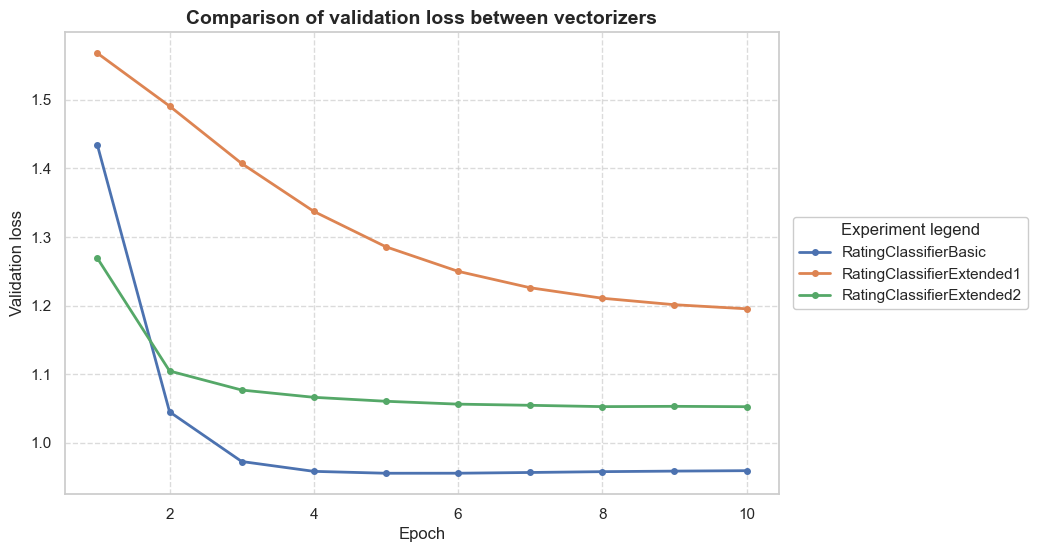

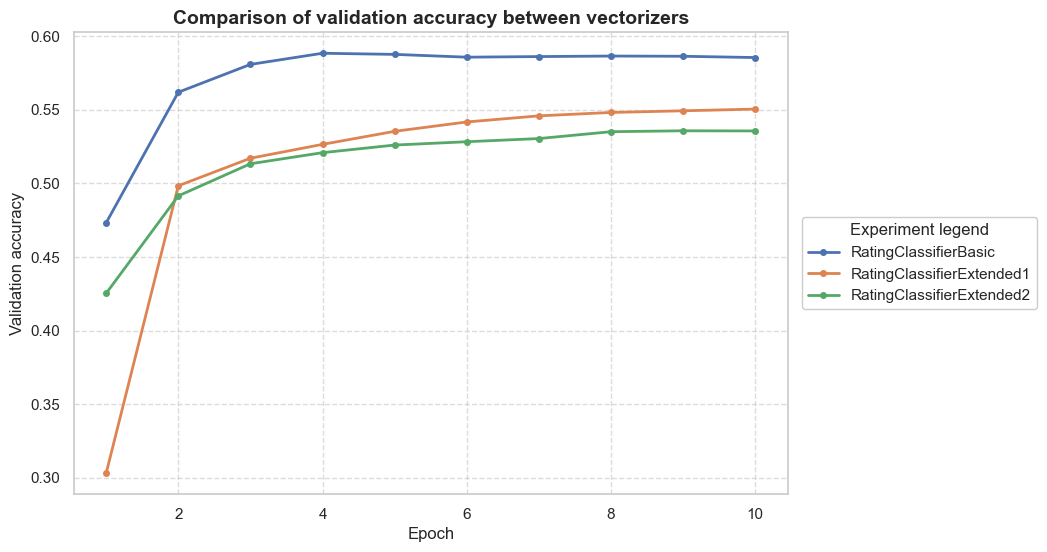

In [82]:
models = {
    "RatingClassifierBasic": RatingClassifier(vocab_size, labels_num),
    "RatingClassifierExtended1": RatingClassifierExtendedV1(vocab_size, labels_num),
    "RatingClassifierExtended2": RatingClassifierExtendedV2(vocab_size, labels_num),
}

all_tested_losses = {}
all_tested_acc = {}


num_epochs = 10

for model_alias, model in models.items():
    
    model.to(device)
    print(model)

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-5)
    lr_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs, eta_min=1e-5)


    run = wandb.init(project="MyExperiments")
    accumulated_loss, accumulated_acc = train(model, data_loaders, criterion, optimizer, lr_scheduler, num_epochs)
    run.finish()
    
    all_tested_losses[model_alias] = accumulated_loss
    all_tested_acc[model_alias] = accumulated_acc


plot_comparison(all_tested_losses, title="Comparison of validation loss between vectorizers", ylabel="Validation loss")
plot_comparison(all_tested_acc, title="Comparison of validation accuracy between vectorizers", ylabel="Validation accuracy")


#### Find best model hiperparams and training stage params

Testing:

RatingClassifierExtendedV2(
  (feature_extractor): Sequential(
    (0): Linear(in_features=10000, out_features=256, bias=True)
    (1): LeakyReLU(negative_slope=0.01)
    (2): Linear(in_features=256, out_features=128, bias=True)
    (3): LeakyReLU(negative_slope=0.01)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): LeakyReLU(negative_slope=0.01)
    (6): Linear(in_features=64, out_features=32, bias=True)
    (7): LeakyReLU(negative_slope=0.01)
    (8): Linear(in_features=32, out_features=16, bias=True)
    (9): LeakyReLU(negative_slope=0.01)
  )
  (dropout): Dropout(p=0.1, inplace=False)
  (linear): Linear(in_features=16, out_features=5, bias=True)
)
AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    initial_lr: 5e-05
    lr: 1.6666666666666667e-05
    maximize: False
    weight_decay: 1e-05
)
('linearLR'

100%|██████████| 305/305 [00:05<00:00, 58.37it/s]


(Epoch 1/[train]) Loss:	1.614   Accuracy: 0.199   lr: 1.6666666666666667e-05


100%|██████████| 77/77 [00:01<00:00, 62.79it/s]


(Epoch 1/[val]) Loss:	1.613   Accuracy: 0.200   lr: 1.6666666666666667e-05


...

(Epoch 5/[train]) Loss:	1.611   Accuracy: 0.199   lr: 0.01


100%|██████████| 77/77 [00:01<00:00, 60.36it/s]
wandb: ERROR The nbformat package was not found. It is required to save notebook history.


(Epoch 5/[val]) Loss:	1.611   Accuracy: 0.198   lr: 0.01


train/accuracy,████▁
train/loss,█▆▄▂▁
train/lr,▁▁▁▁▁
val/accuracy,▁▁▁▁▁
val/loss,█▆▄▂▁
val/lr,▁▁▁▁▁
train/accuracy,0.19851
train/loss,1.611
train/lr,0.01
val/accuracy,0.19805
val/loss,1.61085


/var/folders/w2/3khqjd7d1m97phfx15lm1wyr0000gn/T/ipykernel_38679/828334386.py:8: MatplotlibDeprecationWarning: Passing label as a length 3 sequence when plotting a single dataset is deprecated in Matplotlib 3.9 and will error in 3.11.  To keep the current behavior, cast the sequence to string before passing.
  plt.plot(epochs, metrics_val, label=model_name, linewidth=2, marker='o', markersize=4)


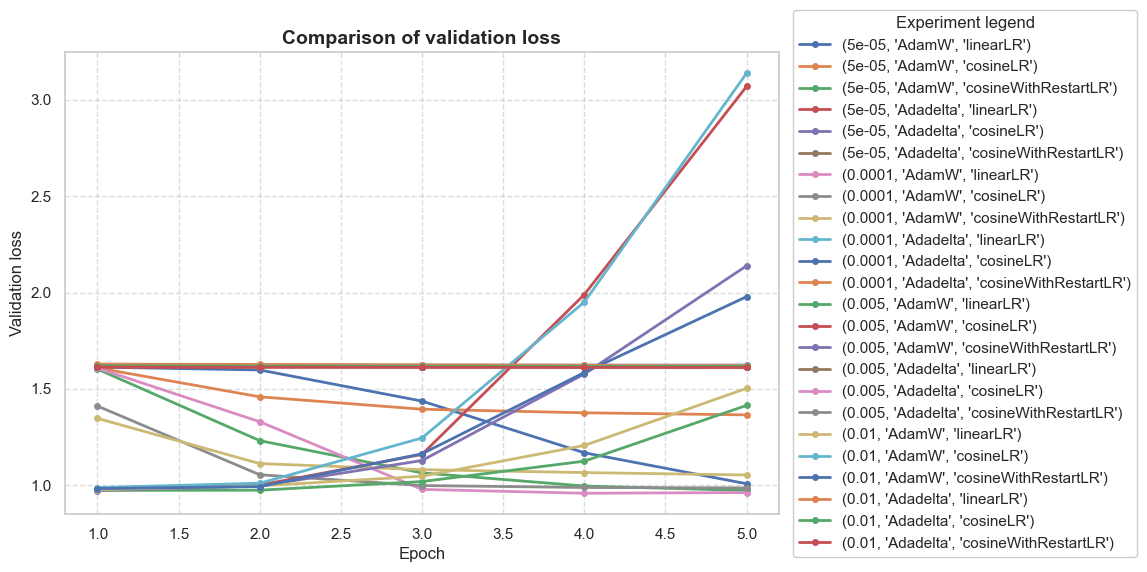

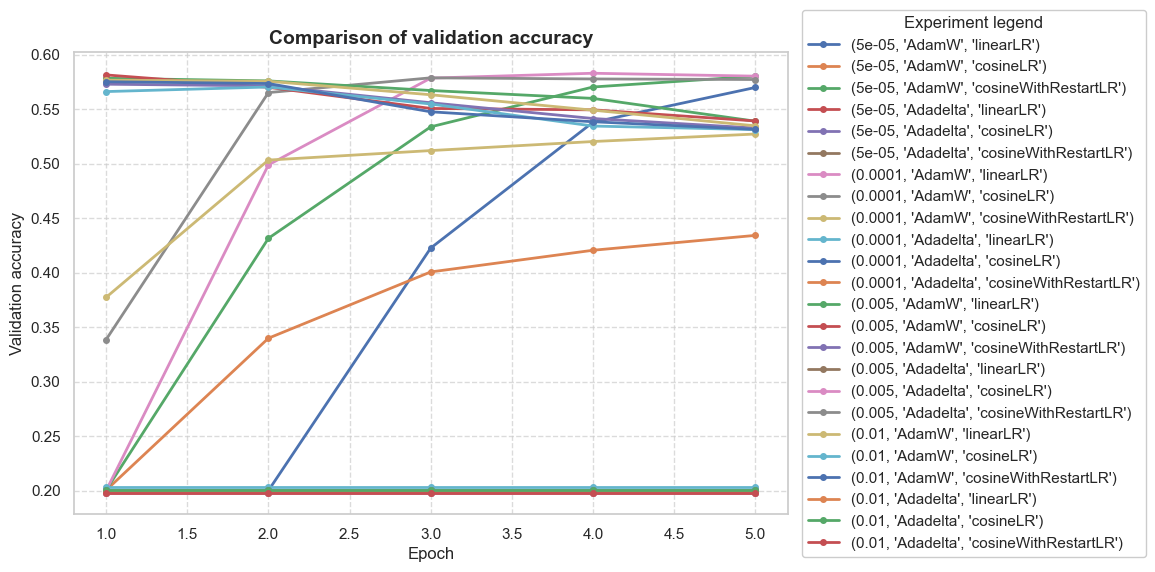

In [83]:
from itertools import product

all_tested_losses = {}
all_tested_acc = {}

num_epochs = 5

learning_rates = [5e-5, 1e-4, 5e-3, 1e-2]
optims = [("AdamW", torch.optim.AdamW), ("Adadelta", torch.optim.Adadelta)]
schedulers = [("linearLR", torch.optim.lr_scheduler.LinearLR), ("cosineLR", torch.optim.lr_scheduler.CosineAnnealingLR), ("cosineWithRestartLR", torch.optim.lr_scheduler.CosineAnnealingWarmRestarts)]

for params in product(learning_rates, optims, schedulers):
    lr, optim, scheduler = params
    optim_alias, optimizer = optim
    scheduler_alias, lr_scheduler = scheduler

    best_model = RatingClassifierExtendedV2(vocab_size, labels_num)
    best_model.to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = optimizer(best_model.parameters(), lr=lr, weight_decay=1e-5)
    if scheduler_alias == "linearLR":
        lr_scheduler = lr_scheduler(optimizer, total_iters=num_epochs)
    elif scheduler_alias == "cosineLR":
        lr_scheduler = lr_scheduler(optimizer, T_max=num_epochs, eta_min=1e-5)
    else:
        lr_scheduler = lr_scheduler(optimizer, T_0=1, eta_min=1e-5)

    print("Testing:\n")
    print(best_model)
    print(optimizer)
    print(f"{scheduler}\n")
        
    run = wandb.init(project="MyExperiments")
    accumulated_loss, accumulated_acc = train(best_model, data_loaders, criterion, optimizer, lr_scheduler, num_epochs)
    run.finish()
    
    all_tested_losses[(lr, optim_alias, scheduler_alias)] = accumulated_loss
    all_tested_acc[(lr, optim_alias, scheduler_alias)] = accumulated_acc


plot_comparison(all_tested_losses, title="Comparison of validation loss", ylabel="Validation loss")
plot_comparison(all_tested_acc, title="Comparison of validation accuracy", ylabel="Validation accuracy")


- best found config: optim - `AdamW`, lr - `lr=5e-5`, scheduler -`CosineAnnealingWarmRestarts` 

#### Check infulenece of epochs number on loss and accuracy - goal is to find margin where model doesn't learn anymore or can overfit 

- used best hiperparams + training params found in previous step (optimizer, scheduler, lr) 

In [84]:
all_tested_losses = {}
all_tested_acc = {}

print("Checking epochs number influence on training:\n")

model = RatingClassifierExtendedV2(vocab_size, labels_num)
model.to(device)
    
num_epochs = 100
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=5e-5, weight_decay=1e-5)
lr_scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(optimizer, T_0=10, eta_min=1e-5)

print(model)
print(optimizer)
print(lr_scheduler)
    
run = wandb.init(project="MyExperiments")
accumulated_loss, accumulated_acc = train(model, data_loaders, criterion, optimizer, lr_scheduler, num_epochs)
run.finish()

all_tested_losses[(lr, optim_alias, scheduler_alias)] = accumulated_loss
all_tested_acc[(lr, optim_alias, scheduler_alias)] = accumulated_acc

Checking epochs number influence on training:

RatingClassifierExtendedV2(
  (feature_extractor): Sequential(
    (0): Linear(in_features=10000, out_features=256, bias=True)
    (1): LeakyReLU(negative_slope=0.01)
    (2): Linear(in_features=256, out_features=128, bias=True)
    (3): LeakyReLU(negative_slope=0.01)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): LeakyReLU(negative_slope=0.01)
    (6): Linear(in_features=64, out_features=32, bias=True)
    (7): LeakyReLU(negative_slope=0.01)
    (8): Linear(in_features=32, out_features=16, bias=True)
    (9): LeakyReLU(negative_slope=0.01)
  )
  (dropout): Dropout(p=0.1, inplace=False)
  (linear): Linear(in_features=16, out_features=5, bias=True)
)
AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    initial_lr: 5e-05
    lr: 5e-05
    maximize: False
    weight_decay:

100%|██████████| 305/305 [00:05<00:00, 52.49it/s]


(Epoch 1/[train]) Loss:	1.616   Accuracy: 0.201   lr: 5e-05


100%|██████████| 77/77 [00:01<00:00, 62.62it/s]


(Epoch 1/[val]) Loss:	1.577   Accuracy: 0.198   lr: 5e-05


...

100%|██████████| 305/305 [05:47<00:00,  1.14s/it]


(Epoch 100/[train]) Loss:	0.333   Accuracy: 0.892   lr: 1.097886967409693e-05


100%|██████████| 77/77 [00:01<00:00, 60.34it/s]
wandb: ERROR The nbformat package was not found. It is required to save notebook history.


(Epoch 100/[val]) Loss:	2.223   Accuracy: 0.527   lr: 1.097886967409693e-05


train/accuracy,▁▁▁▁▂▂▃▃▃▃▃▄▃▄▄▄▄▄▄▄▄▄▄▄▄▅▅▅▅▅▆▆▆▇▇▇▇███
train/loss,████▇▇▇▇▇▇▆▆▆▆▆▆▅▅▅▅▅▅▅▄▄▄▄▃▃▃▃▂▂▂▂▂▂▂▁▁
train/lr,█▇▃▂▂█▆▂█▆▁█▇▆▃▇▆▂▁█▆▂▂██▇▄▂█▇▆▂▁█▇▃▂▁█▃
val/accuracy,▁▇▇▇▇████████████████████████████▇▇▇▇▇▇▇
val/loss,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▂▂▂▂▂▂▂▃▃▃▄▄▄▅▅▅▆▇▇█
val/lr,██▇▇▆▂▁▇▆▂█▆▂█▇▄▃▁█▇▄▃▂▁█▇▇▆▂▇▂▂▃▂▃▁█▇▇▂
train/accuracy,0.8924
train/loss,0.33291
train/lr,1e-05
val/accuracy,0.52677
val/loss,2.2229


/var/folders/w2/3khqjd7d1m97phfx15lm1wyr0000gn/T/ipykernel_38679/828334386.py:8: MatplotlibDeprecationWarning: Passing label as a length 3 sequence when plotting a single dataset is deprecated in Matplotlib 3.9 and will error in 3.11.  To keep the current behavior, cast the sequence to string before passing.
  plt.plot(epochs, metrics_val, label=model_name, linewidth=2, marker='o', markersize=4)


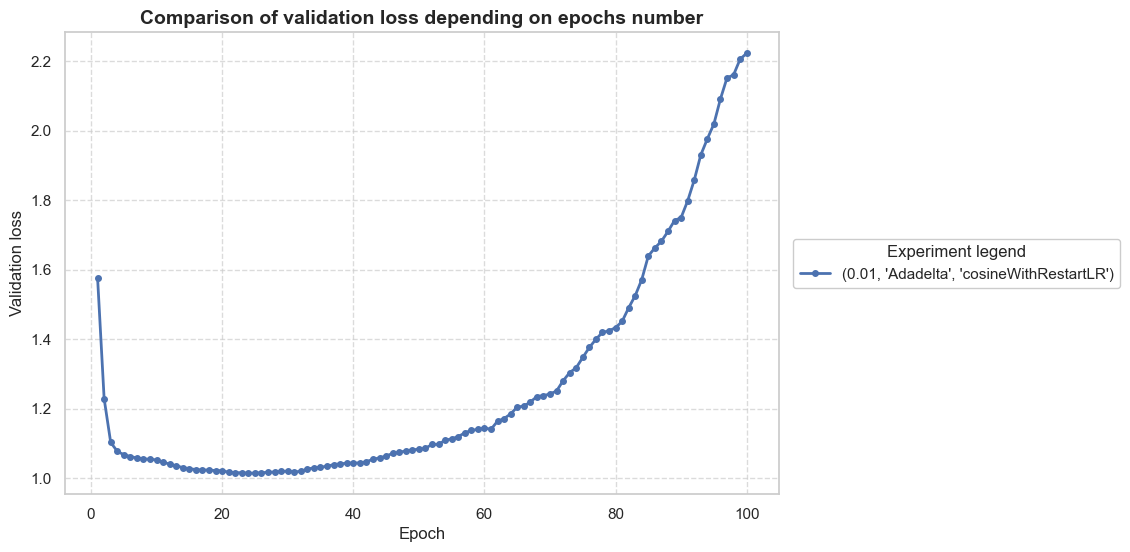

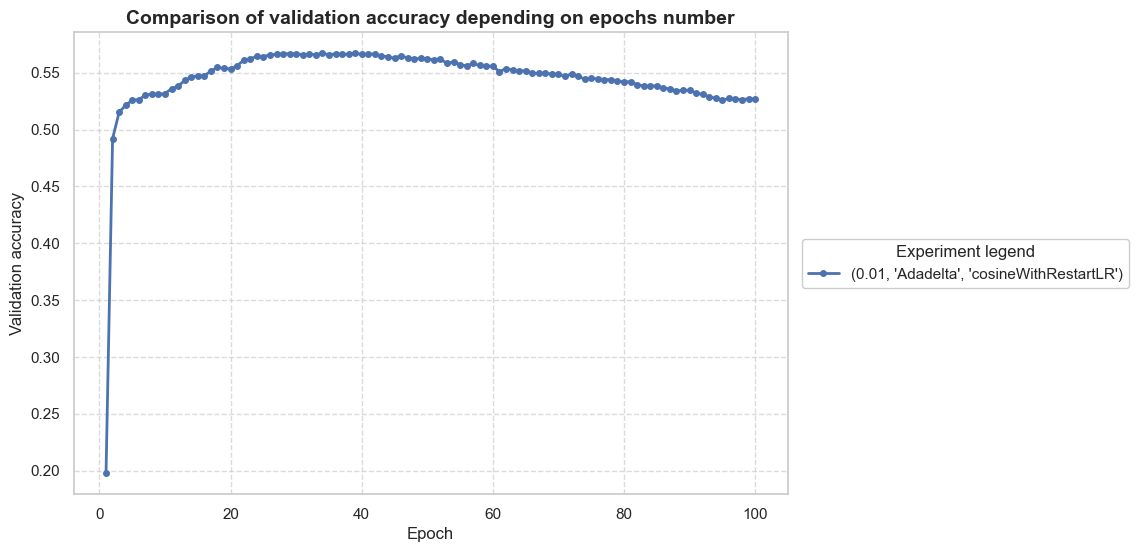

In [85]:
plot_comparison(all_tested_losses, title="Comparison of validation loss depending on epochs number", ylabel="Validation loss")
plot_comparison(all_tested_acc, title="Comparison of validation accuracy depending on epochs number", ylabel="Validation accuracy")

- optimal number of epochs for selected model, hiperparams, training params: circa `20 epochs`

## Final model

### Test Model with best eval acc-loss ratio

In [86]:
model = RatingClassifierExtendedV2(vocab_size, labels_num)
model.to(device)

num_epochs = 20
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=5e-5, weight_decay=1e-5)
lr_scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(optimizer, T_0=10, eta_min=1e-5)

print(model)
print(optimizer)
print(lr_scheduler)
    
run = wandb.init(project="MyExperiments")
accumulated_loss, accumulated_acc = train(model, data_loaders, criterion, optimizer, lr_scheduler, num_epochs)
run.finish()

all_tested_losses[(lr, optim_alias, scheduler_alias)] = accumulated_loss
all_tested_acc[(lr, optim_alias, scheduler_alias)] = accumulated_acc

RatingClassifierExtendedV2(
  (feature_extractor): Sequential(
    (0): Linear(in_features=10000, out_features=256, bias=True)
    (1): LeakyReLU(negative_slope=0.01)
    (2): Linear(in_features=256, out_features=128, bias=True)
    (3): LeakyReLU(negative_slope=0.01)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): LeakyReLU(negative_slope=0.01)
    (6): Linear(in_features=64, out_features=32, bias=True)
    (7): LeakyReLU(negative_slope=0.01)
    (8): Linear(in_features=32, out_features=16, bias=True)
    (9): LeakyReLU(negative_slope=0.01)
  )
  (dropout): Dropout(p=0.1, inplace=False)
  (linear): Linear(in_features=16, out_features=5, bias=True)
)
AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    initial_lr: 5e-05
    lr: 5e-05
    maximize: False
    weight_decay: 1e-05
)


100%|██████████| 305/305 [00:05<00:00, 52.44it/s]


(Epoch 1/[train]) Loss:	1.615   Accuracy: 0.207   lr: 5e-05


100%|██████████| 77/77 [00:01<00:00, 69.68it/s]


(Epoch 1/[val]) Loss:	1.606   Accuracy: 0.274   lr: 5e-05


...

100%|██████████| 305/305 [00:04<00:00, 63.11it/s]


(Epoch 20/[train]) Loss:	0.848   Accuracy: 0.638   lr: 1.097886967409693e-05


100%|██████████| 77/77 [00:01<00:00, 66.68it/s]
wandb: ERROR The nbformat package was not found. It is required to save notebook history.


(Epoch 20/[val]) Loss:	0.994   Accuracy: 0.577   lr: 1.097886967409693e-05


train/accuracy,▁▃▅▆▆▆▇▇▇▇▇▇████████
train/loss,█▇▄▃▃▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁
train/lr,██▇▇▆▄▃▂▂▁██▇▇▆▄▃▂▂▁
val/accuracy,▁▄▆▇▇▇██████████████
val/loss,█▅▃▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val/lr,██▇▇▆▄▃▂▂▁██▇▇▆▄▃▂▂▁
train/accuracy,0.63786
train/loss,0.8485
train/lr,1e-05
val/accuracy,0.57687
val/loss,0.9938


/var/folders/w2/3khqjd7d1m97phfx15lm1wyr0000gn/T/ipykernel_38679/828334386.py:8: MatplotlibDeprecationWarning: Passing label as a length 3 sequence when plotting a single dataset is deprecated in Matplotlib 3.9 and will error in 3.11.  To keep the current behavior, cast the sequence to string before passing.
  plt.plot(epochs, metrics_val, label=model_name, linewidth=2, marker='o', markersize=4)


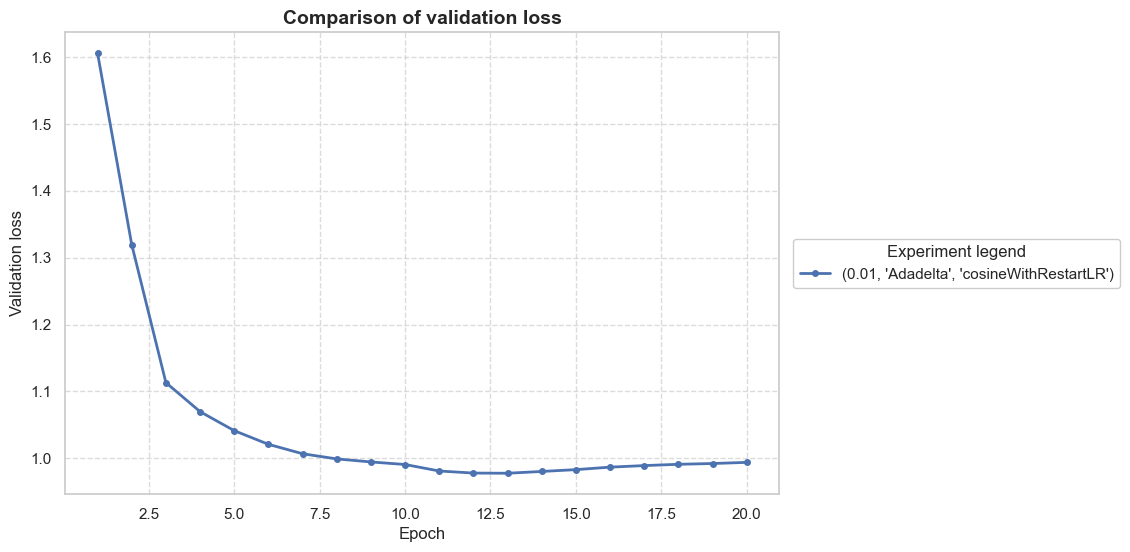

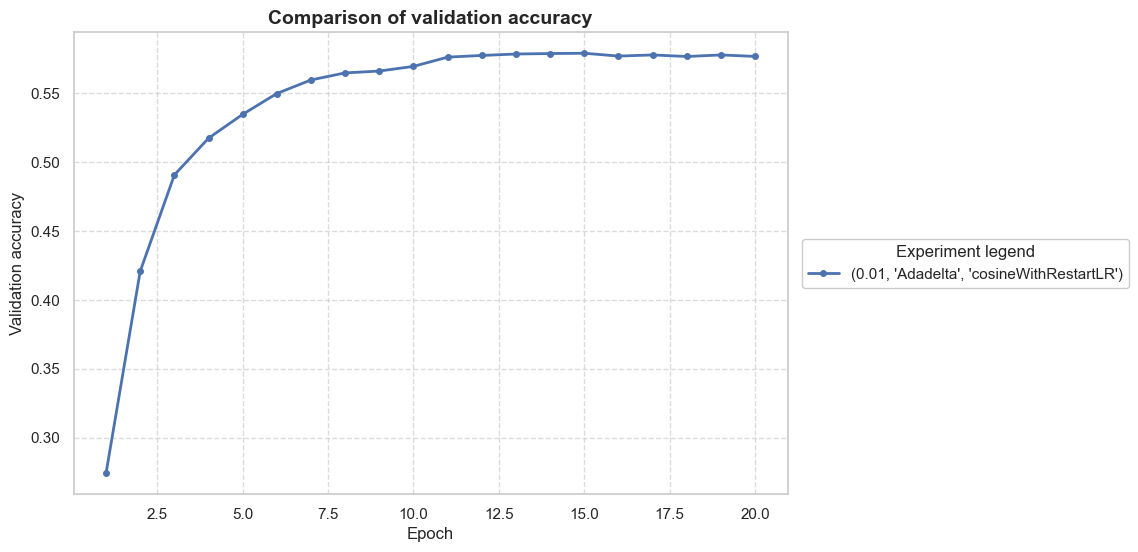

In [87]:
plot_comparison(all_tested_losses, title="Comparison of validation loss", ylabel="Validation loss")
plot_comparison(all_tested_acc, title="Comparison of validation accuracy", ylabel="Validation accuracy")

#### Test final model on test dataset

100%|██████████| 30/30 [00:00<00:00, 63.49it/s]


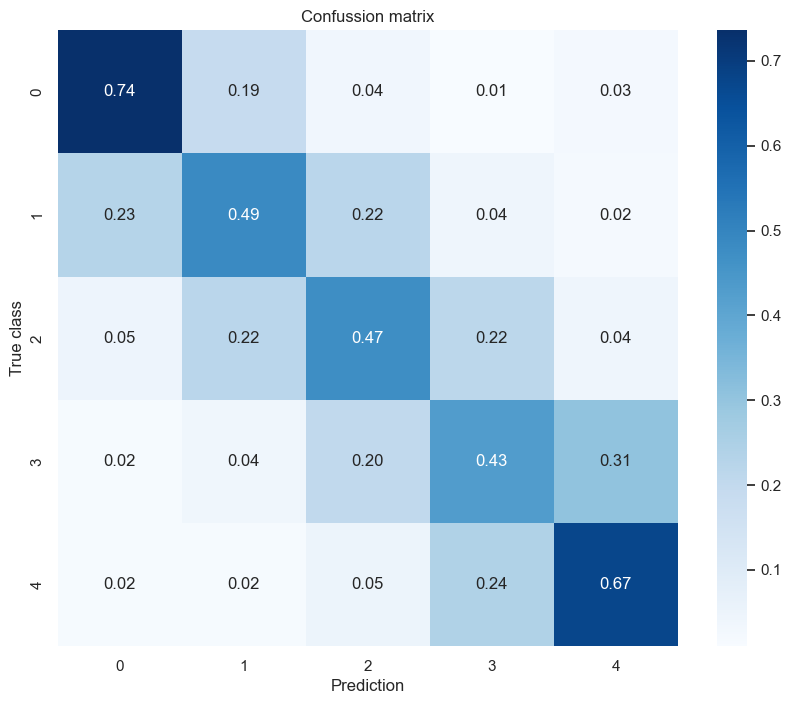

In [88]:
logits_l = []
preds_l = []
targets_l = []
input_l = []

model.eval()
with torch.inference_mode():
    for X_batch, target in tqdm(data_loaders['test']):
        X_batch, target = X_batch.to(device), target.to(device)
        logits = model(X_batch)
        _, preds = torch.max(logits, dim=-1)
        preds_l.append(preds.cpu())
        logits_l.append(logits.cpu())
        targets_l.append(target.cpu())
        input_l.append(X_batch.cpu())

all_logits = torch.cat(logits_l, dim=0)
all_preds = torch.cat(preds_l, dim=0)
all_targets = torch.cat(targets_l, dim=0)
all_input = torch.cat(input_l, dim=0)

plot_confusion_matrix(all_targets.numpy(), all_preds.numpy())

#### Save final model

In [89]:
torch.save(model.state_dict(), 'my_best_model_weights.pth')